# AURORA SCORE — Implementación técnica del modelo de scoring alternativo (v1)
**Vertex Financial Group · Gestión de Proyectos de Datos (SCY1102) · Evaluación Parcial 3**
Integrantes: Areliz Isla · Daniela Montefinale

Este cuaderno implementa la **Release 1 (MVP del piloto Chile–Perú)** del plan de proyecto, siguiendo las fases CRISP-DM de *Data Understanding → Data Preparation → Modeling → Evaluation → Deployment (automatización)*.
Cubre los 8 pasos de la Guía 3.1.2:

| Paso | Contenido | Sección |
|---|---|---|
| 1 | Cargar el dataset del proyecto | §1 |
| 2 | Analizar las clases y generar gráficos representativos | §2 |
| 3 | Preparar los datos y seleccionar variable dependiente e independientes | §3 |
| 4 | Separar en entrenamiento y test | §4 |
| 5 | Entrenar el modelo y analizar si la preparación fue suficiente | §5 |
| 6 | Evaluar con métricas de desempeño (+ auditoría de equidad y explicabilidad) | §6 |
| 7 | Generar 5 predicciones con datos nuevos | §7 |
| 8 | Proponer e implementar una automatización | §8 |

> **Nota sobre los datos:** el caso no entrega un dataset. Se construyó un **dataset sintético** de 12.000 créditos (la cartera piloto descrita en la sección 9 del caso) con el script `src/generar_dataset.py` (semilla fija 2026). Sus variables, tasas y sesgos replican lo descrito en las secciones 3, 4, 6 y 7 del caso. Ver `docs/diccionario_datos.md`.

In [1]:
# Configuración (funciona en Google Colab y en local)
import sys, os, json, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install shap
    REPO = "https://github.com/areeislat/aurora-score"
    if not os.path.exists("aurora-score"):
        !git clone -q {REPO}
    os.chdir("aurora-score")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap, joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, precision_score,
                             recall_score, f1_score, classification_report)

SEED = 42
FIG = "reports/figures"; os.makedirs(FIG, exist_ok=True); os.makedirs("models", exist_ok=True)
# Paleta validada (dataviz): azul, naranjo, aqua; gris para contexto; rojo solo para umbrales críticos
AZUL, NARANJO, AQUA, GRIS, ROJO, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#1baf7a", "#b9b8b2", "#e34948", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": GRIS, "axes.labelcolor": TINTA2,
                     "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.6})
def guardar(nombre):
    plt.tight_layout(); plt.savefig(f"{FIG}/{nombre}.png", bbox_inches="tight", facecolor="white"); plt.show()
print("Entorno listo · Colab:", IN_COLAB)

Entorno listo · Colab: True


## 1. Carga del dataset (Paso 1)

In [2]:
df_raw = pd.read_csv("data/aurora_cartera_piloto.csv")
print(f"Registros: {len(df_raw):,} · Columnas: {df_raw.shape[1]}")
df_raw.head()

Registros: 12,060 · Columnas: 34


,id_credito,fecha_otorgamiento,pais,ciudad_piloto,genero,edad,zona_residencia,sector_laboral,antiguedad_linea_meses,tipo_plan,...,tiempo_llenado_seg,cambios_monto_solicitud,sesiones_previas_app,opt_in_redes,antiguedad_cuenta_redes_meses,tamano_red_contactos,monto_credito_usd,plazo_meses,tasa_interes_mensual,incumplimiento
0,AUR-09824,2025-09-10,Chile,Santiago,Femenino,32,Periurbana,Informal,17.0,Prepago,...,101.0,1,2,Sí,36.0,35.0,340.0,4,0.032,0
1,AUR-11755,2025-05-26,Chile,Santiago,Masculino,57,Urbana,Formal,46.0,Prepago,...,228.0,1,3,No,NaN,NaN,330.0,5,0.032,0
2,AUR-10940,2025-04-12,Chile,Santiago,Masculino,37,Urbana,Informal,29.0,Prepago,...,250.0,1,8,No,NaN,NaN,230.0,6,0.032,0
3,AUR-11209,2025-08-03,Chile,Santiago,Femenino,44,Periurbana,Informal,67.0,Prepago,...,307.0,1,3,Sí,72.0,63.0,400.0,4,0.032,0
4,AUR-03979,2025-07-07,Perú,Lima,Masculino,65,Urbana,Formal,21.0,Prepago,...,139.0,0,1,No,NaN,NaN,490.0,6,0.032,1


In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12060 entries, 0 to 12059
Data columns (total 34 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_credito                     12060 non-null  object 
 1   fecha_otorgamiento             12060 non-null  object 
 2   pais                           12060 non-null  object 
 3   ciudad_piloto                  12060 non-null  object 
 4   genero                         12060 non-null  object 
 5   edad                           12060 non-null  int64  
 6   zona_residencia                12060 non-null  object 
 7   sector_laboral                 12060 non-null  object 
 8   antiguedad_linea_meses         12060 non-null  float64
 9   tipo_plan                      12060 non-null  object 
 10  recarga_prom_mensual_usd       8871 non-null   float64
 11  pct_pagos_plan_a_tiempo        3189 non-null   float64
 12  gama_dispositivo               12060 non-null 

## 2. Análisis de clases y exploración (Paso 2)
La variable objetivo es `incumplimiento` (1 = mora ≥ 60 días). Primero revisamos el balance de clases, luego la calidad de los datos y la representatividad de la muestra (sesgo histórico detectado en la auditoría del caso).

incumplimiento
0    10780
1     1280 
Tasa de incumplimiento: 10.6%  (supuesto del caso, Año 1: 11,0%)


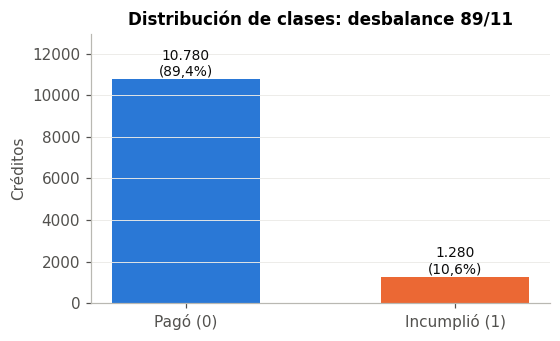

In [4]:
clases = df_raw["incumplimiento"].value_counts().sort_index()
tasa = df_raw["incumplimiento"].mean()
print(clases.to_string(), f"\nTasa de incumplimiento: {tasa:.1%}  (supuesto del caso, Año 1: 11,0%)")

fig, ax = plt.subplots(figsize=(5.2, 3.2))
bars = ax.bar(["Pagó (0)", "Incumplió (1)"], clases.values, color=[AZUL, NARANJO], width=0.55)
for b, v in zip(bars, clases.values):
    ax.text(b.get_x() + b.get_width()/2, v + 150, f"{v:,}".replace(",", ".") + f"\n({v/clases.sum():.1%})".replace(".", ","), ha="center", color=TINTA, fontsize=9)
ax.set_ylabel("Créditos"); ax.set_title("Distribución de clases: desbalance 89/11"); ax.set_ylim(0, clases.max()*1.2); ax.grid(axis="x", visible=False)
guardar("fig01_clases")

{
 "duplicados": 60,
 "etiquetas_tipo_plan": [
  "Prepago",
  "Postpago",
  "PREPAGO ",
  "post-pago"
 ],
 "outliers_tiempo_llenado(>3000s)": 25,
 "registros_con_rezago_72h": 1206
}


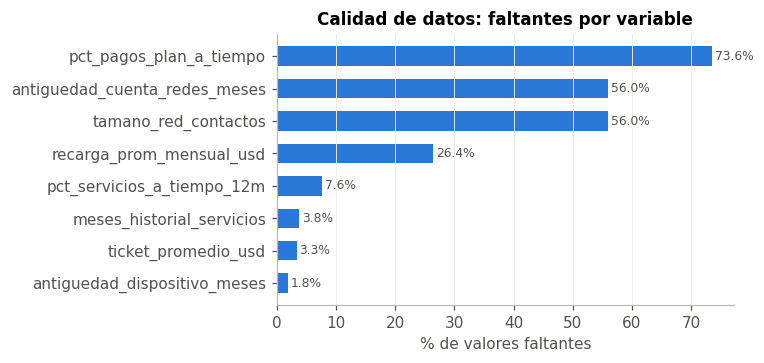

Nota: los nulos de recarga/pct_pagos_plan son estructurales (dependen de prepago/postpago) y los de redes sociales corresponden a solicitantes sin opt-in.


In [5]:
# Calidad de datos: nulos, duplicados, etiquetas inconsistentes y outliers
nulos = (df_raw.isna().mean()*100).sort_values(ascending=False)
nulos = nulos[nulos > 0]
calidad = {
    "duplicados": int(df_raw.duplicated().sum()),
    "etiquetas_tipo_plan": df_raw["tipo_plan"].unique().tolist(),
    "outliers_tiempo_llenado(>3000s)": int((df_raw["tiempo_llenado_seg"] > 3000).sum()),
    "registros_con_rezago_72h": int((df_raw["rezago_dato_servicios_h"] == 72).sum()),
}
print(json.dumps(calidad, indent=1, ensure_ascii=False))

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(nulos.index[::-1], nulos.values[::-1], color=AZUL, height=0.6)
for i, v in enumerate(nulos.values[::-1]): ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8, color=TINTA2)
ax.set_xlabel("% de valores faltantes"); ax.set_title("Calidad de datos: faltantes por variable"); ax.grid(axis="y", visible=False)
guardar("fig02_calidad_datos")
print("Nota: los nulos de recarga/pct_pagos_plan son estructurales (dependen de prepago/postpago) y los de redes sociales corresponden a solicitantes sin opt-in.")

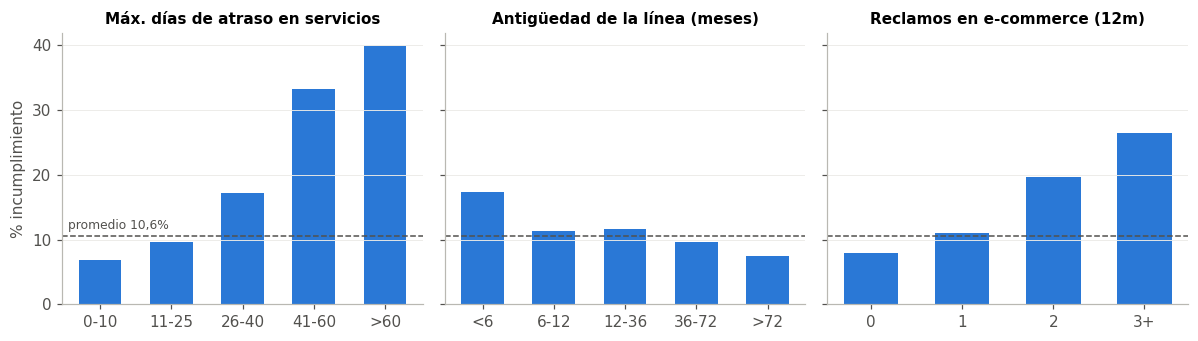

In [6]:
# Tasa de incumplimiento según variables de comportamiento de pago (gráficos representativos)
d = df_raw.copy()
d["atraso_servicios"] = pd.cut(d["max_dias_atraso_servicios"], [-1, 10, 25, 40, 60, 999], labels=["0-10", "11-25", "26-40", "41-60", ">60"])
d["antig_linea"] = pd.cut(d["antiguedad_linea_meses"], [0, 6, 12, 36, 72, 999], labels=["<6", "6-12", "12-36", "36-72", ">72"])
d["reclamos"] = d["reclamos_12m"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, col, tit in zip(axes, ["atraso_servicios", "antig_linea", "reclamos"],
                        ["Máx. días de atraso en servicios", "Antigüedad de la línea (meses)", "Reclamos en e-commerce (12m)"]):
    t = d.groupby(col, observed=True)["incumplimiento"].mean()*100
    ax.bar(t.index.astype(str), t.values, color=AZUL, width=0.6)
    ax.axhline(tasa*100, color=TINTA2, ls="--", lw=1); ax.set_title(tit, fontsize=10); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% incumplimiento"); axes[0].text(-0.45, tasa*100 + 1.0, f"promedio {tasa:.1%}".replace(".", ","), ha="left", fontsize=8, color=TINTA2)
guardar("fig03_eda_riesgo")

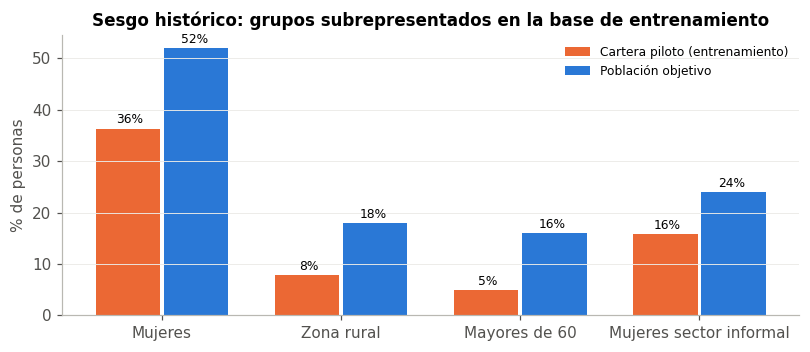

zona_residencia
Periurbana    10.8
Rural          9.5
Urbana        10.7


In [7]:
# Representatividad: composición de la cartera piloto vs. población objetivo (sesgo histórico, sección 7 del caso)
# Población objetivo de referencia (supuesto documentado: adultos no bancarizados de las ciudades piloto)
poblacion_obj = {"Mujeres": 0.52, "Zona rural": 0.18, "Mayores de 60": 0.16, "Mujeres sector informal": 0.24}
muestra = {"Mujeres": (df_raw.genero == "Femenino").mean(), "Zona rural": (df_raw.zona_residencia == "Rural").mean(),
           "Mayores de 60": (df_raw.edad > 60).mean(),
           "Mujeres sector informal": ((df_raw.genero == "Femenino") & (df_raw.sector_laboral == "Informal")).mean()}
rep = pd.DataFrame({"Cartera piloto": muestra, "Población objetivo": poblacion_obj})*100
x = np.arange(len(rep)); w = 0.36
fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.bar(x - w/2 - 0.01, rep["Cartera piloto"], w, color=NARANJO, label="Cartera piloto (entrenamiento)")
ax.bar(x + w/2 + 0.01, rep["Población objetivo"], w, color=AZUL, label="Población objetivo")
for i, (a, b) in enumerate(rep.values): ax.text(i - w/2, a + 1, f"{a:.0f}%", ha="center", fontsize=8); ax.text(i + w/2, b + 1, f"{b:.0f}%", ha="center", fontsize=8)
ax.set_xticks(x, rep.index); ax.set_ylabel("% de personas"); ax.legend(frameon=False, fontsize=8); ax.grid(axis="x", visible=False)
ax.set_title("Sesgo histórico: grupos subrepresentados en la base de entrenamiento")
guardar("fig04_representatividad")
# El riesgo REAL no difiere entre grupos:
print((df_raw.groupby("zona_residencia")["incumplimiento"].mean()*100).round(1).to_string())

## 3. Preparación de datos y selección de variables (Paso 3)
Decisiones de preparación (trazables al reporte de calidad):
1. **Eliminar 60 duplicados** generados por reenvíos de la API de la operadora.
2. **Normalizar etiquetas** de `tipo_plan` (`PREPAGO `, `post-pago`).
3. **Outliers de la app** (`tiempo_llenado_seg = 99999`, timeouts) → se tratan como faltantes.
4. **Imputación** por mediana con *indicador de faltante* (el faltante es informativo: rezago de 72 h, sin opt-in).
5. **Ingeniería de variables:** `llenado_rapido` (< 110 s, posible bot), `linea_nueva` (< 6 meses), `cuota_estimada_usd`.
6. **Variable dependiente:** `incumplimiento`. **Independientes:** variables de comportamiento de las fuentes alternativas.
7. **Excluidas del modelo por diseño ético:** género, edad, zona y sector laboral (se conservan *solo* para auditar equidad), además de identificadores y variables constantes.

In [8]:
df = df_raw.drop_duplicates().copy()
df["tipo_plan"] = df["tipo_plan"].str.strip().str.lower().replace({"post-pago": "postpago"}).str.capitalize()
df.loc[df["tiempo_llenado_seg"] > 3000, "tiempo_llenado_seg"] = np.nan
df["llenado_rapido"] = (df["tiempo_llenado_seg"] < 110).astype(int)
df["linea_nueva"] = (df["antiguedad_linea_meses"] < 6).astype(int)
r = df["tasa_interes_mensual"]
df["cuota_estimada_usd"] = (df["monto_credito_usd"] * r / (1 - (1 + r) ** -df["plazo_meses"])).round(1)

SENSIBLES = ["genero", "edad", "zona_residencia", "sector_laboral"]
EXCLUIR = ["id_credito", "fecha_otorgamiento", "pais", "ciudad_piloto", "tasa_interes_mensual", "incumplimiento"] + SENSIBLES
PROXIES = ["gama_dispositivo", "sistema_operativo", "tipo_plan", "recarga_prom_mensual_usd", "ticket_promedio_usd", "antiguedad_dispositivo_meses"]
y = df["incumplimiento"]
X = df.drop(columns=EXCLUIR)
CAT = X.select_dtypes(include=["object", "string"]).columns.tolist()
NUM = [c for c in X.columns if c not in CAT]
print(f"Registros tras limpieza: {len(df):,} · Variables candidatas: {X.shape[1]} ({len(NUM)} numéricas, {len(CAT)} categóricas)")
print("Categóricas:", CAT)

Registros tras limpieza: 12,000 · Variables candidatas: 27 (23 numéricas, 4 categóricas)
Categóricas: ['tipo_plan', 'gama_dispositivo', 'sistema_operativo', 'opt_in_redes']


In [9]:
# Detección de variables proxy: correlación de cada variable con los atributos sensibles (que NO entran al modelo)
grupo_vuln = ((df.zona_residencia == "Rural") | (df.edad > 60) | ((df.genero == "Femenino") & (df.sector_laboral == "Informal"))).astype(int)
Xn = pd.get_dummies(X, columns=CAT, drop_first=True).astype(float)
corr = Xn.apply(lambda c: c.corr(grupo_vuln)).abs().sort_values(ascending=False).head(8)
print("Correlación |r| con pertenencia a grupo subrepresentado:\n", corr.round(3).to_string())

Correlación |r| con pertenencia a grupo subrepresentado:
 gama_dispositivo_Baja            0.324
transacciones_mes                0.308
meses_actividad_billetera        0.276
ticket_promedio_usd              0.204
antiguedad_cuenta_redes_meses    0.201
recarga_prom_mensual_usd         0.198
meses_historial_servicios        0.174
tipo_plan_Prepago                0.162


## 4. Separación en entrenamiento y test (Paso 4)
División estratificada 75/25 para conservar la tasa de incumplimiento en ambos conjuntos.

In [10]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"Train: {len(X_tr):,} ({y_tr.mean():.1%} incumpl.) · Test: {len(X_te):,} ({y_te.mean():.1%} incumpl.)")
sens_te = df.loc[X_te.index, SENSIBLES]

Train: 9,000 (10.7% incumpl.) · Test: 3,000 (10.7% incumpl.)


## 5. Entrenamiento de modelos (Paso 5)
- **Baseline interpretable:** regresión logística (scorecard tradicional).
- **Modelo del caso:** gradient boosting (`HistGradientBoostingClassifier`), con ajuste de hiperparámetros por validación cruzada estratificada de 5 pliegues.
- Ambos dentro de un `Pipeline` de scikit-learn → la misma preparación se aplica en entrenamiento, test y producción (reproducibilidad).

In [11]:
def preprocesador(num, cat, escalar=True):
    num_pipe = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("esc", StandardScaler())] if escalar else [])
    return ColumnTransformer([("num", Pipeline(num_pipe), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)], verbose_feature_names_out=False)

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
modelos = {
    "Regresión logística": Pipeline([("prep", preprocesador(NUM, CAT)), ("modelo", LogisticRegression(max_iter=3000, C=0.5))]),
    "Gradient boosting": Pipeline([("prep", preprocesador(NUM, CAT, escalar=False)),
                                   ("modelo", HistGradientBoostingClassifier(random_state=SEED))]),
}
grid = GridSearchCV(modelos["Gradient boosting"], {"modelo__learning_rate": [0.03, 0.06], "modelo__max_depth": [3, 5],
                    "modelo__max_iter": [200, 300], "modelo__min_samples_leaf": [60, 150], "modelo__l2_regularization": [1.0]},
                    scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_tr, y_tr)
modelos["Gradient boosting"] = grid.best_estimator_
print("Mejores hiperparámetros GB:", {k.split("__")[1]: v for k, v in grid.best_params_.items()})
cv_res = {}
for nombre, m in modelos.items():
    s = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="roc_auc", n_jobs=-1); cv_res[nombre] = s
    m.fit(X_tr, y_tr)
    print(f"{nombre:22s} AUC CV = {s.mean():.3f} ± {s.std():.3f}")

Mejores hiperparámetros GB: {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 200, 'min_samples_leaf': 150}
Regresión logística    AUC CV = 0.748 ± 0.021
Gradient boosting      AUC CV = 0.737 ± 0.019


In [12]:
# ¿Fue suficiente la preparación? Comparamos AUC train vs test (sobreajuste) y el aporte de la limpieza
for nombre, m in modelos.items():
    a_tr, a_te = roc_auc_score(y_tr, m.predict_proba(X_tr)[:,1]), roc_auc_score(y_te, m.predict_proba(X_te)[:,1])
    diag = "sin sobreajuste relevante" if a_tr - a_te < 0.05 else "sobreajuste moderado: se controla con regularización y se vigila en CV"
    print(f"{nombre:22s} AUC train={a_tr:.3f} · test={a_te:.3f} · brecha={a_tr-a_te:.3f} → {diag}")
print("\nLa AUC en test es cercana a la de validación cruzada (diferencia ≈ 0,02), por lo que la estimación es estable."
      " Las variables construidas en la preparación (linea_nueva, llenado_rapido, indicadores de faltante) aparecen entre"
      " las más relevantes (§6.3): la preparación fue suficiente para un MVP; el límite actual es la cantidad de variables (27 vs 240+).")

Regresión logística    AUC train=0.758 · test=0.719 · brecha=0.040 → sin sobreajuste relevante
Gradient boosting      AUC train=0.801 · test=0.721 · brecha=0.080 → sobreajuste moderado: se controla con regularización y se vigila en CV

La AUC en test es cercana a la de validación cruzada (diferencia ≈ 0,02), por lo que la estimación es estable. Las variables construidas en la preparación (linea_nueva, llenado_rapido, indicadores de faltante) aparecen entre las más relevantes (§6.3): la preparación fue suficiente para un MVP; el límite actual es la cantidad de variables (27 vs 240+).


## 6. Evaluación con métricas de desempeño (Paso 6)
### 6.1 Métricas técnicas
En scoring crediticio se usan **AUC-ROC, Gini (= 2·AUC − 1) y KS**; además *precision/recall* del incumplimiento en el punto de corte de negocio.

**Política de decisión (con supervisión humana, comprometida en el informe de factibilidad):**
- PD bajo el percentil 70 → **Aprobación automática**
- PD entre percentil 70 y 85 → **Revisión humana** (zona gris)
- PD sobre percentil 85 → **Rechazo con motivos explicados y derecho a apelación**

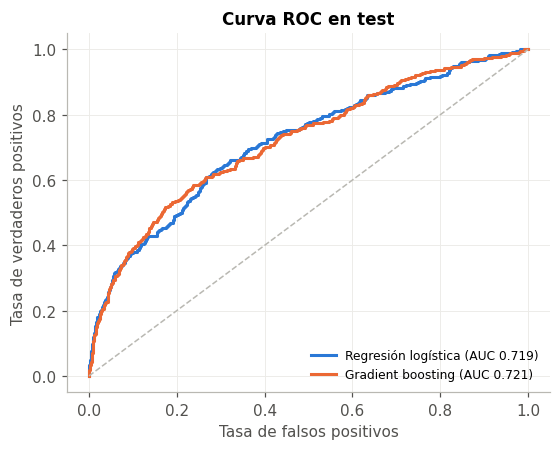

,AUC,Gini,KS
Regresión logística,0.719,0.437,0.343
Gradient boosting,0.721,0.442,0.347


In [13]:
def ks_stat(y, p):
    f, t, _ = roc_curve(y, p); return float(np.max(t - f))
res = {}
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for (nombre, m), col in zip(modelos.items(), [AZUL, NARANJO]):
    p = m.predict_proba(X_te)[:, 1]; auc = roc_auc_score(y_te, p)
    res[nombre] = {"AUC": auc, "Gini": 2*auc - 1, "KS": ks_stat(y_te, p)}
    f, t, _ = roc_curve(y_te, p); ax.plot(f, t, color=col, lw=2, label=f"{nombre} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1); ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curva ROC en test"); ax.legend(frameon=False, fontsize=8, loc="lower right")
guardar("fig05_roc")
pd.DataFrame(res).T.round(3)

### 6.2 Auditoría de equidad (mitigación de sesgo comprometida en EP1)
**Regla de selección del campeón (fijada antes de entrenar):** mayor AUC entre los modelos que cumplen equidad.

Métrica: **razón de impacto dispar** = tasa de aprobación del grupo / tasa del grupo de referencia. Umbral de aceptación: **≥ 0,80** (regla de los 4/5).
Se comparan: (a) modelo con todas las variables y (b) modelos (LR y GB) **sin variables proxy** (gama y antigüedad del teléfono, sistema operativo, tipo de plan, recarga, ticket promedio) y con **re-ponderación ×2** de los grupos subrepresentados.

,LR original,GB original,LR mitigado,GB mitigado
Mujeres vs hombres,0.928,0.924,0.963,0.928
Rural vs urbana,0.707,0.747,0.773,0.814
Mayores de 60 vs resto,0.741,0.730,0.813,0.845
Mujer informal vs resto,0.842,0.865,0.906,0.884


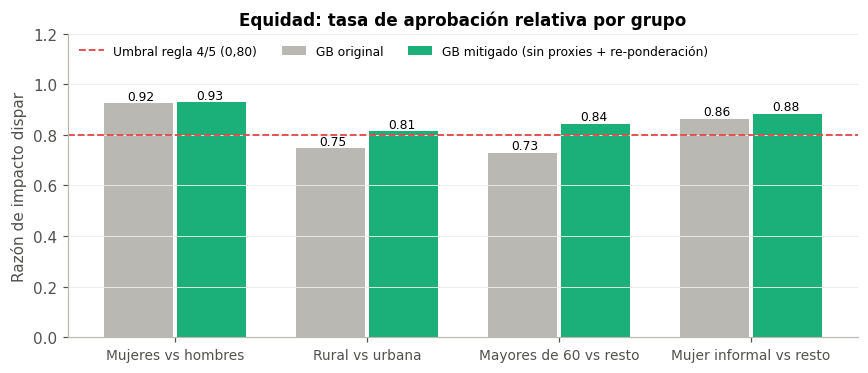

In [14]:
def politica(p, ref):
    c70, c85 = np.quantile(ref, [0.70, 0.85])
    return np.where(p < c70, "Aprobar", np.where(p < c85, "Revisión humana", "Rechazar")), c70, c85

def impacto_dispar(aprob, s):
    grupos = {"Mujeres vs hombres": (s.genero == "Femenino", s.genero == "Masculino"),
              "Rural vs urbana": (s.zona_residencia == "Rural", s.zona_residencia == "Urbana"),
              "Mayores de 60 vs resto": (s.edad > 60, s.edad <= 60),
              "Mujer informal vs resto": ((s.genero == "Femenino") & (s.sector_laboral == "Informal"),
                                           ~((s.genero == "Femenino") & (s.sector_laboral == "Informal")))}
    return {g: aprob[a].mean() / aprob[b].mean() for g, (a, b) in grupos.items()}

# (b) Modelo mitigado: sin proxies + re-ponderación de grupos subrepresentados
NUM_M = [c for c in NUM if c not in PROXIES]; CAT_M = [c for c in CAT if c not in PROXIES]
s_tr = df.loc[X_tr.index]
vuln_tr = (s_tr.zona_residencia == "Rural") | (s_tr.edad > 60) | ((s_tr.genero == "Femenino") & (s_tr.sector_laboral == "Informal"))
gb_params = {k.split("__")[1]: v for k, v in grid.best_params_.items()}
modelo_mitigado = Pipeline([("prep", preprocesador(NUM_M, CAT_M, escalar=False)),
                            ("modelo", HistGradientBoostingClassifier(random_state=SEED, **gb_params))])
modelo_mitigado.fit(X_tr[NUM_M + CAT_M], y_tr, modelo__sample_weight=np.where(vuln_tr, 2.0, 1.0))

lr_mitigado = Pipeline([("prep", preprocesador(NUM_M, CAT_M)), ("modelo", LogisticRegression(max_iter=3000, C=0.5))])
lr_mitigado.fit(X_tr[NUM_M + CAT_M], y_tr, modelo__sample_weight=np.where(vuln_tr, 2.0, 1.0))
candidatos = {"LR original": (modelos["Regresión logística"], list(X.columns)), "GB original": (modelos["Gradient boosting"], list(X.columns)),
              "LR mitigado": (lr_mitigado, NUM_M + CAT_M), "GB mitigado": (modelo_mitigado, NUM_M + CAT_M)}
eq, res = {}, {}
for nombre, (m, cols) in candidatos.items():
    p = m.predict_proba(X_te[cols])[:, 1]
    dec, _, _ = politica(p, p)
    eq[nombre] = impacto_dispar(pd.Series(dec == "Aprobar", index=X_te.index), sens_te)
    auc = roc_auc_score(y_te, p)
    res[nombre] = {"AUC": auc, "Gini": 2*auc - 1, "KS": ks_stat(y_te, p),
                   "Mora en aprobados": y_te[dec == "Aprobar"].mean(), "Aprobación automática": (dec == "Aprobar").mean(),
                   "Impacto dispar mínimo": min(eq[nombre].values())}
eq = pd.DataFrame(eq)
display(eq.round(3))
x = np.arange(len(eq)); w = 0.36
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(x - w/2 - 0.01, eq["GB original"], w, color=GRIS, label="GB original")
ax.bar(x + w/2 + 0.01, eq["GB mitigado"], w, color=AQUA, label="GB mitigado (sin proxies + re-ponderación)")
for i, (a, b) in enumerate(eq[["GB original", "GB mitigado"]].values): ax.text(i - w/2, a + 0.015, f"{a:.2f}", ha="center", fontsize=8); ax.text(i + w/2, b + 0.015, f"{b:.2f}", ha="center", fontsize=8)
ax.axhline(0.8, color=ROJO, ls="--", lw=1.2, label="Umbral regla 4/5 (0,80)")
ax.set_xticks(x, eq.index, fontsize=9); ax.set_ylim(0, 1.15); ax.set_ylabel("Razón de impacto dispar"); ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=3); ax.set_ylim(0, 1.2); ax.set_title("Equidad: tasa de aprobación relativa por grupo")
guardar("fig06_equidad")

In [15]:
metricas = pd.DataFrame(res).T
display(metricas.round(3))
# Regla de selección (definida antes de entrenar): mayor AUC entre los modelos con impacto dispar mínimo >= 0,80
aptos = metricas[metricas["Impacto dispar mínimo"] >= 0.80]
NOMBRE_CAMPEON = aptos["AUC"].idxmax()
print(f"Modelos que cumplen equidad: {list(aptos.index)} → CAMPEÓN: {NOMBRE_CAMPEON}")
print("Los modelos originales quedan descartados aunque su AUC sea similar: no cumplen la regla 4/5 con población rural y mayores de 60.")

,AUC,Gini,KS,Mora en aprobados,Aprobación automática,Impacto dispar mínimo
LR original,0.719,0.437,0.343,0.062,0.7,0.707
GB original,0.721,0.442,0.347,0.060,0.7,0.730
LR mitigado,0.708,0.416,0.305,0.067,0.7,0.773
GB mitigado,0.717,0.434,0.326,0.066,0.7,0.814


Modelos que cumplen equidad: ['GB mitigado'] → CAMPEÓN: GB mitigado
Los modelos originales quedan descartados aunque su AUC sea similar: no cumplen la regla 4/5 con población rural y mayores de 60.


Precision=0.202 · Recall=0.569 · F1=0.298


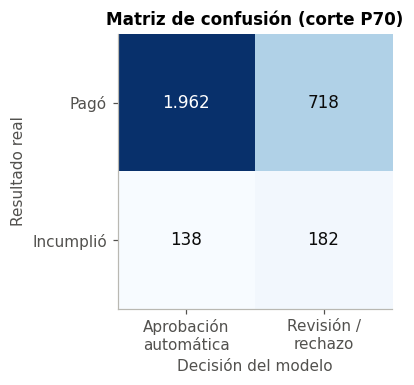

Mora cartera piloto: 10.7% → mora en aprobados automáticos: 6.6% (reducción 38%)


In [16]:
# Matriz de confusión del campeón en el punto de corte de aprobación automática (P70)
campeon, COLS = candidatos[NOMBRE_CAMPEON]
p_te = campeon.predict_proba(X_te[COLS])[:, 1]
dec_te, C70, C85 = politica(p_te, p_te)
pred_riesgo = (dec_te != "Aprobar").astype(int)   # 1 = no se aprueba automáticamente
cm = confusion_matrix(y_te, pred_riesgo)
print(f"Precision={precision_score(y_te, pred_riesgo):.3f} · Recall={recall_score(y_te, pred_riesgo):.3f} · F1={f1_score(y_te, pred_riesgo):.3f}")
fig, ax = plt.subplots(figsize=(4.4, 3.6))
ax.imshow(cm, cmap="Blues"); ax.grid(False)
for i in range(2):
    for j in range(2): ax.text(j, i, f"{cm[i,j]:,}".replace(",", "."), ha="center", va="center", color="white" if cm[i,j] > cm.max()/2 else TINTA, fontsize=11)
ax.set_xticks([0, 1], ["Aprobación\nautomática", "Revisión /\nrechazo"]); ax.set_yticks([0, 1], ["Pagó", "Incumplió"])
ax.set_xlabel("Decisión del modelo"); ax.set_ylabel("Resultado real"); ax.set_title("Matriz de confusión (corte P70)")
guardar("fig07_confusion")
mora_base, mora_aprob = y_te.mean(), y_te[dec_te == "Aprobar"].mean()
print(f"Mora cartera piloto: {mora_base:.1%} → mora en aprobados automáticos: {mora_aprob:.1%} (reducción {1 - mora_aprob/mora_base:.0%})")

### 6.3 Explicabilidad (derecho a explicación)
Se usan **valores SHAP** para (a) la importancia global de las variables y (b) los motivos individuales de rechazo que se comunican al solicitante.

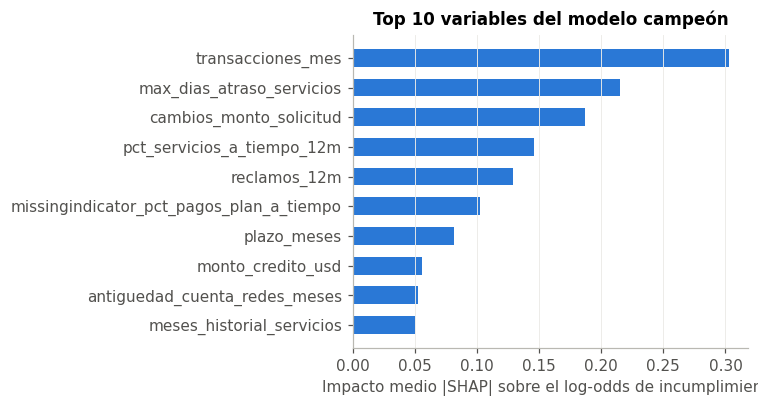

In [17]:
prep_c, gb_c = campeon.named_steps["prep"], campeon.named_steps["modelo"]
Xt_te = pd.DataFrame(prep_c.transform(X_te[COLS]), columns=prep_c.get_feature_names_out())
FONDO = pd.DataFrame(prep_c.transform(X_tr[COLS].sample(500, random_state=SEED)), columns=Xt_te.columns)
explainer = shap.TreeExplainer(gb_c) if hasattr(gb_c, "max_iter") and not hasattr(gb_c, "coef_") else shap.LinearExplainer(gb_c, FONDO)
sv = np.asarray(explainer.shap_values(Xt_te))
imp = pd.Series(np.abs(sv).mean(0), index=Xt_te.columns).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index[::-1], imp.values[::-1], color=AZUL, height=0.6); ax.grid(axis="y", visible=False)
ax.set_xlabel("Impacto medio |SHAP| sobre el log-odds de incumplimiento"); ax.set_title("Top 10 variables del modelo campeón")
guardar("fig08_shap_importancia")

## 7. Predicciones con datos nuevos (Paso 7)
Se aplican el modelo y la política a **5 solicitudes nuevas** (`data/nuevas_solicitudes.csv`), con sus 3 principales motivos.

In [18]:
ETIQ = {"max_dias_atraso_servicios": "atrasos en pago de servicios básicos", "pct_servicios_a_tiempo_12m": "puntualidad en servicios básicos",
        "antiguedad_linea_meses": "antigüedad de la línea móvil", "linea_nueva": "línea móvil muy reciente",
        "llenado_rapido": "formulario completado anormalmente rápido", "tiempo_llenado_seg": "tiempo de llenado del formulario",
        "reclamos_12m": "reclamos en comercio electrónico", "cambios_monto_solicitud": "cambios del monto solicitado",
        "tasa_devoluciones": "tasa de devoluciones", "pct_pagos_plan_a_tiempo": "puntualidad del plan móvil",
        "monto_credito_usd": "monto solicitado", "cuota_estimada_usd": "cuota estimada", "plazo_meses": "plazo",
        "meses_historial_servicios": "historial en servicios básicos", "transacciones_mes": "uso de billetera digital",
        "meses_actividad_billetera": "antigüedad en billetera digital", "sesiones_previas_app": "uso previo de la app",
        "tamano_red_contactos": "tamaño de red social (opt-in)", "antiguedad_cuenta_redes_meses": "antigüedad de cuenta en redes (opt-in)",
        "opt_in_redes_No": "sin autorización de redes sociales", "opt_in_redes_Sí": "autorización de redes sociales",
        "rezago_dato_servicios_h": "rezago del dato de servicios"}
def preparar(dfn):
    dfn = dfn.copy()
    dfn["tipo_plan"] = dfn["tipo_plan"].str.strip().str.lower().replace({"post-pago": "postpago"}).str.capitalize()
    dfn.loc[dfn["tiempo_llenado_seg"] > 3000, "tiempo_llenado_seg"] = np.nan
    dfn["llenado_rapido"] = (dfn["tiempo_llenado_seg"] < 110).astype(int)
    dfn["linea_nueva"] = (dfn["antiguedad_linea_meses"] < 6).astype(int)
    r = dfn["tasa_interes_mensual"]; dfn["cuota_estimada_usd"] = (dfn["monto_credito_usd"]*r/(1-(1+r)**-dfn["plazo_meses"])).round(1)
    return dfn
def motivos(fila_sv, nombres, k=3):
    orden = np.argsort(-fila_sv)[:k]
    return "; ".join(ETIQ.get(nombres[i].replace("missingindicator_", ""), nombres[i]) for i in orden if fila_sv[i] > 0) or "—"

nuevas = preparar(pd.read_csv("data/nuevas_solicitudes.csv"))
p_all = campeon.predict_proba(nuevas[COLS])[:, 1]
orden = np.argsort(p_all)   # 5 casos representativos de todo el rango de riesgo
muestra5 = nuevas.iloc[[orden[10], orden[80], orden[140], orden[175], orden[195]]]
pd5 = campeon.predict_proba(muestra5[COLS])[:, 1]
sv5 = np.asarray(explainer.shap_values(pd.DataFrame(prep_c.transform(muestra5[COLS]), columns=Xt_te.columns)))
nombres = prep_c.get_feature_names_out()
pred5 = pd.DataFrame({"id_solicitud": muestra5["id_solicitud"].values, "monto_usd": muestra5["monto_credito_usd"].values,
                      "prob_incumplimiento": pd5.round(3),
                      "decision": np.where(pd5 < C70, "Aprobar", np.where(pd5 < C85, "Revisión humana", "Rechazar")),
                      "principales_factores_de_riesgo": [motivos(s, nombres) for s in sv5]})
pred5

,id_solicitud,monto_usd,prob_incumplimiento,decision,principales_factores_de_riesgo
0,SOL-0083,220.0,0.024,Aprobar,tiempo de llenado del formulario; uso previo d...
1,SOL-0076,340.0,0.071,Aprobar,uso de billetera digital; puntualidad en servi...
2,SOL-0005,400.0,0.128,Revisión humana,antigüedad de cuenta en redes (opt-in); uso de...
3,SOL-0161,190.0,0.200,Rechazar,reclamos en comercio electrónico; cambios del ...
4,SOL-0012,400.0,0.368,Rechazar,atrasos en pago de servicios básicos; uso de b...


## 8. Automatización (Paso 8)
**Propuesta:** un *job* diario de scoring por lotes que (1) toma las solicitudes del día, (2) aplica el modelo y la política con gate humano, (3) genera motivos de rechazo legibles y (4) controla el **drift** de los datos con el índice PSI, generando alerta si PSI > 0,25.
**Implementación:** se serializa el modelo (`models/aurora_score_v1.joblib`) y el script `src/scoring_batch.py` se ejecuta automáticamente con **GitHub Actions** (`.github/workflows/scoring_diario.yml`, cron 08:00 Chile).

In [19]:
artefacto = {"modelo": campeon, "columnas": COLS, "cortes": {"aprobar": float(C70), "rechazar": float(C85)},
             "referencia_drift": X_tr[NUM_M].describe(percentiles=[.1,.2,.3,.4,.5,.6,.7,.8,.9]).to_dict(),
             "muestra_referencia": X_tr[NUM_M].sample(3000, random_state=SEED), "version": "1.0.0",
             "nombre": NOMBRE_CAMPEON, "fondo_shap": FONDO,
             "metricas_test": {k: float(v) for k, v in res[NOMBRE_CAMPEON].items()}}
joblib.dump(artefacto, "models/aurora_score_v1.joblib")
with open("reports/metricas_modelo.json", "w") as f:
    json.dump({"modelos": {k: {kk: round(float(vv), 4) for kk, vv in v.items()} for k, v in res.items()},
               "impacto_dispar": eq.round(4).to_dict(), "cortes": artefacto["cortes"], "campeon": NOMBRE_CAMPEON,
               "auc_cv": {k: [round(float(v.mean()), 4), round(float(v.std()), 4)] for k, v in cv_res.items()}}, f, indent=2, ensure_ascii=False)
print("Modelo y métricas guardados.")

Modelo y métricas guardados.


In [20]:
# Ejecución de la automatización (lo mismo que corre GitHub Actions cada día)
!python src/scoring_batch.py --entrada data/nuevas_solicitudes.csv --salida reports/

[AURORA] 200 solicitudes procesadas → {'Aprobar': 122, 'Revisión humana': 45, 'Rechazar': 33} · drift: VIGILAR (PSI máx 0.2332)


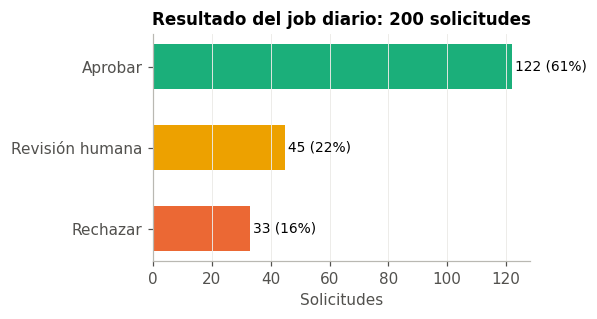

{
  "fecha": "20261123",
  "solicitudes": 200,
  "decisiones": {
    "Aprobar": 122,
    "Revisión humana": 45,
    "Rechazar": 33
  },
  "psi_max": 0.2332,
  "variables_en_alerta": {},
  "estado_drift": "VIGILAR"
}


In [21]:
salida = pd.read_csv(sorted([f"reports/{f}" for f in os.listdir("reports") if f.startswith("scoring_")])[-1])
resumen = salida["decision"].value_counts()
fig, ax = plt.subplots(figsize=(5.5, 3))
cols = {"Aprobar": AQUA, "Revisión humana": "#eda100", "Rechazar": NARANJO}
ax.barh(resumen.index[::-1], resumen.values[::-1], color=[cols[i] for i in resumen.index[::-1]], height=0.55)
for i, v in enumerate(resumen.values[::-1]): ax.text(v + 1, i, f"{v} ({v/resumen.sum():.0%})", va="center", fontsize=9)
ax.set_xlabel("Solicitudes"); ax.set_title(f"Resultado del job diario: {resumen.sum()} solicitudes"); ax.grid(axis="y", visible=False)
guardar("fig09_job_scoring")
print(open("reports/monitoreo_drift.json").read())

## Conclusiones técnicas y registro de avance
| Ítem | Resultado |
|---|---|
| Entregable funcional | Modelo campeón (mitigado) + pipeline + job automatizado con gate humano y monitoreo de drift |
| Desempeño | Ver tabla de métricas §6 (AUC, Gini, KS, mora en aprobados) |
| Equidad | Todos los grupos ≥ 0,80 de impacto dispar tras mitigación |
| Limitaciones | Dataset sintético; ~26 variables vs 240+ del diseño objetivo; la brecha residual en "thin file" requiere un score paralelo (Release 2) |
| Próximo paso | Validación con datos reales del piloto, calibración por país, despliegue de la API < 8 s |

**Reflexión (Guía 3.1):** el componente con mayor impacto en el negocio es el **modelo con su política de decisión**, porque determina directamente la mora (ingreso neto del flujo de caja); pero sin la **automatización** no escala de 45.000 a 590.000 créditos al año, y sin una **comunicación** clara de motivos el regulador no permite operarlo. Los tres son condición necesaria.